# 02 - Model Training and Evaluation
### AutoValue AI | Yash Rajput - 2427010652

This notebook **imports the functions from `src/train.py`** (the same code used by
`python -m src.train`), so the results here match the saved model, the app and the report.

- **7 input fields → 8 model features**: `name` is split into `brand` and `model`.
- Target trained on `log1p(price)`; all metrics are reported in **rupees**.
- 80/20 split (seed 42) → 5-fold CV on the training set → select by CV MAE → evaluate once on test.

In [1]:
import os, sys, warnings
sys.path.insert(0, os.path.abspath(".."))
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt

In [2]:
from src.train import (load_clean_data, split_data, cross_validate_models, select_best, evaluate,
                       grouped_check, permutation_importance_table, plot_mae_comparison,
                       plot_actual_vs_predicted, plot_residuals, plot_importance, MODEL_LABELS)

df, report = load_clean_data()
X_train, X_test, y_train, y_test = split_data(df)
print("clean rows:", len(df), "| train:", len(X_train), "| test:", len(X_test))
X_train.head()

clean rows: 6918 | train: 5534 | test: 1384


,brand,model,fuel,seller_type,transmission,owner,year,km_driven
26,Maruti,Maruti Alto,Petrol,Individual,Manual,First Owner,2017,28000
3484,Ford,Ford EcoSport,Diesel,Individual,Manual,First Owner,2019,20000
63,Hyundai,Hyundai i20,Diesel,Individual,Manual,First Owner,2013,60000
1044,Mahindra,Mahindra Verito,Diesel,Individual,Manual,Second Owner,2012,70000
2594,Jeep,Jeep Compass,Petrol,Dealer,Automatic,First Owner,2019,22000


## Cross-validation comparison (training set only)

In [3]:
searches, table = cross_validate_models(X_train, y_train)
table.assign(cv_mae=table.cv_mae.round(0), cv_mae_std=table.cv_mae_std.round(0),
             cv_rmse=table.cv_rmse.round(0), cv_r2=table.cv_r2.round(3))

,model,cv_mae,cv_mae_std,cv_rmse,cv_r2,best_params
0,linear_regression,84134.0,5386.0,210141.0,0.825,{}
1,gradient_boosting,84433.0,4285.0,221333.0,0.800,"{'max_depth': 5, 'n_estimators': 400}"
2,random_forest,90489.0,3635.0,233779.0,0.776,"{'max_depth': None, 'n_estimators': 400}"


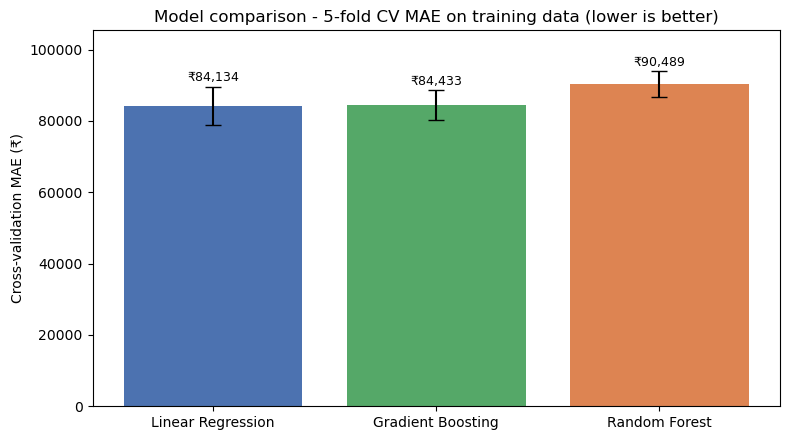

Selected by lowest CV MAE: Linear Regression


In [4]:
plot_mae_comparison(table); plt.show()
best_name = select_best(table)
print("Selected by lowest CV MAE:", MODEL_LABELS[best_name])

All three models use the **same 5-fold CV procedure**. The model is chosen by cross-validation MAE,
never by test performance.

## Final evaluation on the held-out test set

In [5]:
rows = []
for name, s in searches.items():
    m = evaluate(s.best_estimator_, X_test, y_test)
    rows.append({"model": MODEL_LABELS[name], **m})
test_table = pd.DataFrame(rows).sort_values("mae")
test_table.assign(mae=test_table.mae.round(0), rmse=test_table.rmse.round(0), r2=test_table.r2.round(3))

,model,mae,rmse,r2
0,Linear Regression,84331.0,213694.0,0.805
2,Gradient Boosting,84772.0,228885.0,0.777
1,Random Forest,92388.0,238679.0,0.757


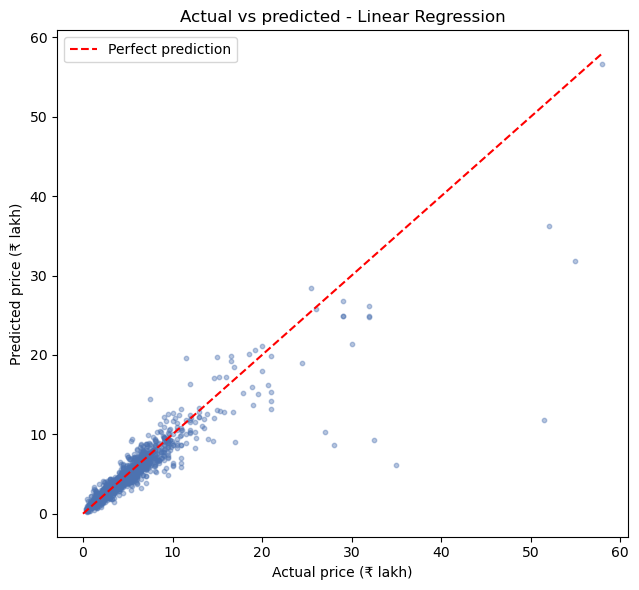

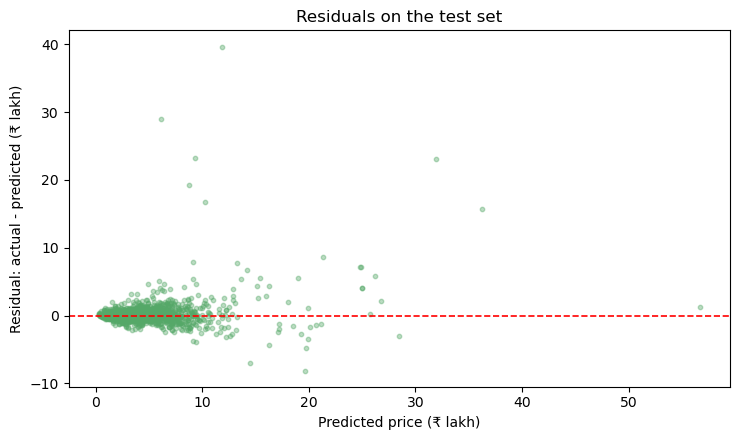

In [6]:
best = searches[best_name].best_estimator_
pred = best.predict(X_test)
plot_actual_vs_predicted(y_test.values, pred, f"Actual vs predicted - {MODEL_LABELS[best_name]}")
plt.show()
plot_residuals(y_test.values, pred); plt.show()

Errors grow with price: cheap and mid-range cars are predicted closely, while the few very expensive
cars have the largest absolute errors - which is why RMSE is much larger than MAE.

## Robustness check - grouped by car model

In [7]:
grouped = grouped_check(best, X_train, y_train)
print("Random 5-fold CV  : MAE ₹{:,.0f}  R² {:.3f}".format(table.iloc[0].cv_mae, table.iloc[0].cv_r2))
print("Grouped by model  : MAE ₹{:,.0f}  R² {:.3f}".format(grouped["mae"], grouped["r2"]))

Random 5-fold CV  : MAE ₹84,134  R² 0.825
Grouped by model  : MAE ₹218,995  R² 0.464


When each validation fold contains **car models never seen in training**, error rises sharply. The
primary (random-split) result applies to car models that are represented in the training data - which
is how the app is used, since it only offers known models. Predictions for unfamiliar or rare models
are much less reliable; this is documented as a limitation.

## Permutation importance (full pipeline)

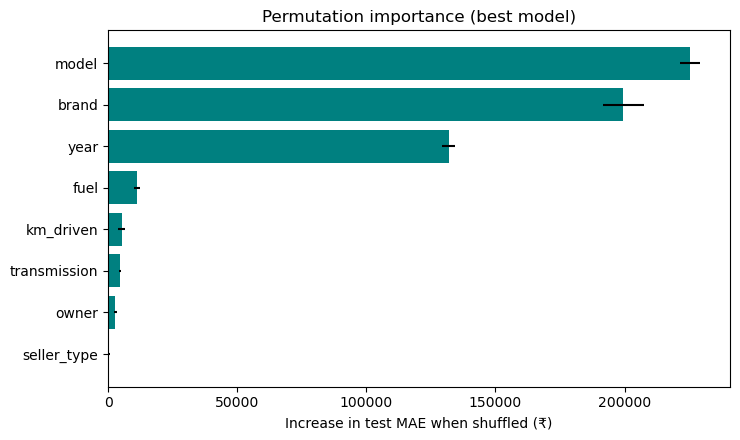

,feature,mae_increase,std
0,model,225512.0,3870.0
1,brand,199492.0,7988.0
2,year,131827.0,2631.0
3,fuel,11099.0,1284.0
4,km_driven,5192.0,1211.0
5,transmission,4621.0,401.0
6,owner,2739.0,672.0
7,seller_type,464.0,169.0


In [8]:
imp = permutation_importance_table(best, X_test, y_test)
plot_importance(imp); plt.show()
imp.assign(mae_increase=imp["mae_increase"].round(0), std=imp["std"].round(0))

Shuffling **model**, **brand** or **year** damages accuracy the most; km driven, transmission, owner
and seller type matter much less once the car model and year are known.